<a href="https://colab.research.google.com/github/Dvithana/bp-classification-brfss2023/blob/main/DS_CW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

BMI Descriptive Statistics:
count    384810.000000
mean         28.465920
std           6.533843
min          12.020000
25%          24.070000
50%          27.390000
75%          31.620000
max          99.840000
Name: bmi, dtype: float64

Q1: 24.07
Q3: 31.62
IQR: 7.55
Lower Bound: 12.74
Upper Bound: 42.94
Potential BMI Outliers: 12264


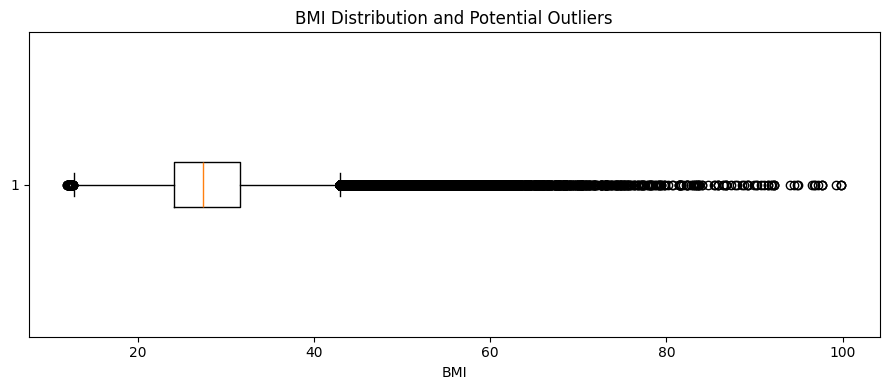

In [ ]:
# ---------------------------------------------------------
# EDA: BMI Outlier Detection
# ---------------------------------------------------------

import matplotlib.pyplot as plt

# BMI descriptive statistics
print("BMI Descriptive Statistics:")
print(X["bmi"].describe())

# IQR method
Q1 = X["bmi"].quantile(0.25)
Q3 = X["bmi"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

outlier_count = (
    (X["bmi"] < lower_bound) |
    (X["bmi"] > upper_bound)
).sum()

print("\nQ1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))
print("Potential BMI Outliers:", outlier_count)

# Boxplot
plt.figure(figsize=(9, 4))

plt.boxplot(
    X["bmi"].dropna(),
    vert=False
)

plt.xlabel("BMI")
plt.title("BMI Distribution and Potential Outliers")

plt.tight_layout()
plt.show()

In [ ]:
# ---------------------------------------------------------
# STEP 14.4.1: Extended Age-Group Performance Analysis
# ---------------------------------------------------------

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


# Add XGBoost probabilities to the evaluation dataframe
evaluation_df["Probability"] = pd.Series(
    y_prob_xgb,
    index=X_test.index
)


age_extended_results = []


for age_group, group_data in evaluation_df.groupby(
    "age_group",
    observed=True
):

    actual = group_data["Actual"]

    predicted = group_data["Predicted"]

    probability = group_data["Probability"]


    age_extended_results.append({

        "Age Group": age_group,

        "Sample Size": len(group_data),

        "High BP Prevalence":
            actual.mean() * 100,

        "Accuracy":
            accuracy_score(
                actual,
                predicted
            ),

        "Balanced Accuracy":
            balanced_accuracy_score(
                actual,
                predicted
            ),

        "Precision":
            precision_score(
                actual,
                predicted,
                zero_division=0
            ),

        "Recall":
            recall_score(
                actual,
                predicted,
                zero_division=0
            ),

        "F1-Score":
            f1_score(
                actual,
                predicted,
                zero_division=0
            ),

        "ROC-AUC":
            roc_auc_score(
                actual,
                probability
            )
    })


age_extended_df = pd.DataFrame(
    age_extended_results
)


# Correct age order
age_order = [
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]


age_extended_df["Age Group"] = pd.Categorical(
    age_extended_df["Age Group"],
    categories=age_order,
    ordered=True
)


age_extended_df = (
    age_extended_df
    .sort_values("Age Group")
)


display(
    age_extended_df.round(4)
)

,Age Group,Sample Size,High BP Prevalence,Accuracy,Balanced Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,18-24,5170,8.4139,0.9155,0.5144,0.4667,0.0322,0.0602,0.7296
1,25-34,8765,13.1204,0.8686,0.5283,0.4936,0.0670,0.1179,0.7374
2,35-44,10870,22.0239,0.7969,0.5805,0.6253,0.1938,0.2959,0.7471
3,45-54,12120,35.4950,0.7085,0.6414,0.6394,0.4100,0.4996,0.7389
4,55-64,15200,47.0724,0.6816,0.6791,0.6700,0.6376,0.6534,0.7472
5,65+,32691,60.5947,0.6710,0.6277,0.6894,0.8319,0.7540,0.7074


In [ ]:
# ---------------------------------------------------------
# HIGH BP PREVALENCE BY AGE GROUP
# ---------------------------------------------------------

age_analysis = (
    evaluation_df
    .groupby(
        "age_group",
        observed=True
    )
    .agg(
        Sample_Size=("Actual", "size"),
        High_BP_Cases=("Actual", "sum"),
        High_BP_Prevalence=("Actual", "mean")
    )
    .reset_index()
)


age_order = [
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]


age_analysis["age_group"] = pd.Categorical(
    age_analysis["age_group"],
    categories=age_order,
    ordered=True
)


age_analysis = (
    age_analysis
    .sort_values("age_group")
)


age_analysis[
    "High_BP_Prevalence"
] = (
    age_analysis[
        "High_BP_Prevalence"
    ] * 100
)


print(
    "High BP Distribution within Test-Set Age Groups:"
)

display(
    age_analysis.round(2)
)

High BP Distribution within Test-Set Age Groups:


,age_group,Sample_Size,High_BP_Cases,High_BP_Prevalence
0,18-24,5170,435,8.41
1,25-34,8765,1150,13.12
2,35-44,10870,2394,22.02
3,45-54,12120,4302,35.50
4,55-64,15200,7155,47.07
5,65+,32691,19809,60.59


In [ ]:
# ---------------------------------------------------------
# RECOVERY: Recreate Variables Needed for Correlation
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ---------------------------------------------------------
# 1. Load original BRFSS 2023 dataset
# ---------------------------------------------------------

file_path = "/content/drive/MyDrive/Data Science/BRFSS2023.csv"

df = pd.read_csv(
    file_path,
    low_memory=False
)


# ---------------------------------------------------------
# 2. Create strict High Blood Pressure target
#    1 = High BP
#    3 = No High BP
# ---------------------------------------------------------

corr_df = df[
    df["bphigh6"].isin([1.0, 3.0])
].copy()

corr_df["High_BP"] = (
    corr_df["bphigh6"]
    .map({
        1.0: 1,
        3.0: 0
    })
)


# ---------------------------------------------------------
# 3. Recreate Age Group
# ---------------------------------------------------------

corr_df["Age_Group"] = corr_df["_age_g"]


# ---------------------------------------------------------
# 4. Recreate BMI
# ---------------------------------------------------------

corr_df["BMI"] = (
    corr_df["_bmi5"] / 100
)


# ---------------------------------------------------------
# 5. Recreate High Cholesterol
# ---------------------------------------------------------

corr_df["High_Cholesterol"] = (
    corr_df["toldhi3"]
    .replace({
        7.0: np.nan,
        9.0: np.nan
    })
    .map({
        1.0: 1,
        2.0: 0
    })
)


# ---------------------------------------------------------
# 6. Recreate Exercise
# ---------------------------------------------------------

corr_df["Exercise"] = (
    corr_df["exerany2"]
    .replace({
        7.0: np.nan,
        9.0: np.nan
    })
    .map({
        1.0: 1,
        2.0: 0
    })
)


# ---------------------------------------------------------
# 7. Convert Alcohol Consumption to Days per Month
# ---------------------------------------------------------

def convert_alcohol_days(value):

    if pd.isna(value):
        return np.nan

    if value in [777, 999]:
        return np.nan

    if value == 888:
        return 0

    # Days per week -> approximate days per month
    if 101 <= value <= 107:
        return (value - 100) * 4.345

    # Days per month
    if 201 <= value <= 230:
        return value - 200

    return np.nan


corr_df["Alcohol_Days"] = (
    corr_df["alcday4"]
    .apply(convert_alcohol_days)
)


# ---------------------------------------------------------
# 8. Keep only variables used for correlation
# ---------------------------------------------------------

correlation_df = corr_df[
    [
        "High_BP",
        "Age_Group",
        "BMI",
        "High_Cholesterol",
        "Exercise",
        "Alcohol_Days"
    ]
].copy()


print("Correlation dataset shape:")
print(correlation_df.shape)

print("\nMissing Values:")
print(correlation_df.isna().sum())

Correlation dataset shape:
(424077, 6)

Missing Values:
High_BP                 0
Age_Group               0
BMI                 39267
High_Cholesterol    53214
Exercise             1148
Alcohol_Days        29157
dtype: int64


In [ ]:
# ---------------------------------------------------------
# STEP 16: Final Project Summary
# ---------------------------------------------------------

# This cell provides a concise summary of the main results
# obtained from the High Blood Pressure classification project.


print("=" * 60)
print("HIGH BLOOD PRESSURE CLASSIFICATION - FINAL SUMMARY")
print("=" * 60)


# ---------------------------------------------------------
# Dataset summary
# ---------------------------------------------------------

print("\nDataset:")
print("BRFSS 2023")

print("\nFinal valid records:")
print(len(prepared_df))


print("\nTarget distribution:")
print(
    (
        prepared_df["high_bp"]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)


# ---------------------------------------------------------
# Final model comparison
# ---------------------------------------------------------

print("\nFinal Models Compared:")
print("- Random Forest")
print("- XGBoost")


print("\nRandom Forest Performance:")
print("Accuracy : 72.74%")
print("Precision: 68.36%")
print("Recall   : 64.02%")
print("F1-Score : 66.12%")
print("ROC-AUC  : 0.7998")


print("\nXGBoost Performance:")
print("Accuracy : 72.97%")
print("Precision: 67.91%")
print("Recall   : 66.28%")
print("F1-Score : 67.08%")
print("ROC-AUC  : 0.8024")


# ---------------------------------------------------------
# Best model
# ---------------------------------------------------------

print("\nBest Performing Model:")
print("XGBoost")


# ---------------------------------------------------------
# Key EDA findings
# ---------------------------------------------------------

print("\nKey EDA Findings:")

print(
    "- High BP prevalence increased strongly with age, "
    "reaching 60.8% among respondents aged 65+."
)

print(
    "- Respondents with diabetes showed 74.2% "
    "High BP prevalence."
)

print(
    "- Obese respondents showed 54.7% "
    "High BP prevalence."
)

print(
    "- Respondents reporting no exercise showed "
    "52.4% High BP prevalence, compared with 38.0% "
    "among those reporting exercise."
)

print(
    "- Former smokers showed the highest observed "
    "High BP prevalence among smoking categories at 50.5%."
)


# ---------------------------------------------------------
# Main XGBoost feature-importance findings
# ---------------------------------------------------------

print("\nImportant XGBoost Features:")

print(
    "- High cholesterol status"
)

print(
    "- Older age groups, particularly 65+"
)

print(
    "- Diabetes status"
)

print(
    "- Age group 55-64"
)

print(
    "- Employment status such as retirement"
)

print(
    "- BMI"
)


print("\nConclusion:")
print(
    "XGBoost provided the strongest overall performance "
    "for classifying High Blood Pressure status in this project."
)

HIGH BLOOD PRESSURE CLASSIFICATION - FINAL SUMMARY

Dataset:
BRFSS 2023

Final valid records:
424077

Target distribution:
high_bp
0    58.45
1    41.55
Name: proportion, dtype: float64

Final Models Compared:
- Random Forest
- XGBoost

Random Forest Performance:
Accuracy : 72.74%
Precision: 68.36%
Recall   : 64.02%
F1-Score : 66.12%
ROC-AUC  : 0.7998

XGBoost Performance:
Accuracy : 72.97%
Precision: 67.91%
Recall   : 66.28%
F1-Score : 67.08%
ROC-AUC  : 0.8024

Best Performing Model:
XGBoost

Key EDA Findings:
- High BP prevalence increased strongly with age, reaching 60.8% among respondents aged 65+.
- Respondents with diabetes showed 74.2% High BP prevalence.
- Obese respondents showed 54.7% High BP prevalence.
- Respondents reporting no exercise showed 52.4% High BP prevalence, compared with 38.0% among those reporting exercise.
- Former smokers showed the highest observed High BP prevalence among smoking categories at 50.5%.

Important XGBoost Features:
- High cholesterol status
-

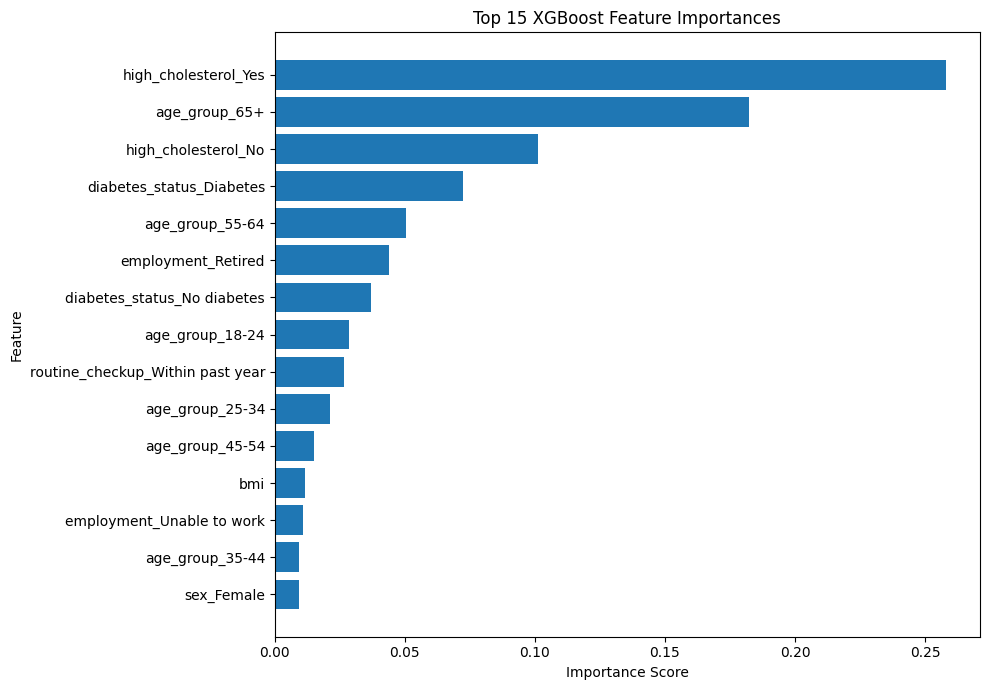

In [ ]:
# ---------------------------------------------------------
# STEP 15.1: Visualise Top 15 XGBoost Feature Importances
# ---------------------------------------------------------

import matplotlib.pyplot as plt


# Select the 15 most important transformed features.
# Sort them from lowest to highest so that the most
# important feature appears at the top of the chart.

top_features = (
    feature_importance_df
    .head(15)
    .sort_values(
        by="Importance",
        ascending=True
    )
)


# ---------------------------------------------------------
# Create horizontal bar chart
# ---------------------------------------------------------

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)


# Add title and axis labels.

plt.title("Top 15 XGBoost Feature Importances")

plt.xlabel("Importance Score")

plt.ylabel("Feature")


# Improve spacing.

plt.tight_layout()


# Display the chart.

plt.show()

In [ ]:
# ---------------------------------------------------------
# STEP 15: Extract XGBoost Feature Importance
# ---------------------------------------------------------

import pandas as pd


# Access the fitted preprocessing step from the trained pipeline.

fitted_preprocessor = xgb_model.named_steps["preprocessor"]


# ---------------------------------------------------------
# Get transformed feature names
# ---------------------------------------------------------

# Numerical feature names remain unchanged.

numeric_feature_names = numerical_features


# Get names created by one-hot encoding for categorical features.

onehot_encoder = (
    fitted_preprocessor
    .named_transformers_["cat"]
    .named_steps["onehot"]
)

categorical_encoded_names = (
    onehot_encoder
    .get_feature_names_out(categorical_features_final)
)


# Combine numerical and categorical transformed feature names.

all_feature_names = (
    list(numeric_feature_names)
    + list(categorical_encoded_names)
)


# ---------------------------------------------------------
# Get XGBoost feature importance scores
# ---------------------------------------------------------

xgb_classifier = xgb_model.named_steps["classifier"]

importance_scores = xgb_classifier.feature_importances_


# ---------------------------------------------------------
# Create and sort the importance table
# ---------------------------------------------------------

feature_importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": importance_scores
})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
)


print("Top 15 XGBoost Features:")

display(
    feature_importance_df.head(15)
)

Top 15 XGBoost Features:


,Feature,Importance
42,high_cholesterol_Yes,0.258209
7,age_group_65+,0.182174
41,high_cholesterol_No,0.101176
43,diabetes_status_Diabetes,0.072299
6,age_group_55-64,0.050271
26,employment_Retired,0.043850
44,diabetes_status_No diabetes,0.037079
2,age_group_18-24,0.028628
57,routine_checkup_Within past year,0.026516
3,age_group_25-34,0.021411


In [ ]:
# ---------------------------------------------------------
# RECOVERY STEP 2: Retrain the XGBoost Model
# ---------------------------------------------------------

from xgboost import XGBClassifier


# Create the same XGBoost pipeline used earlier.

xgb_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            XGBClassifier(
                n_estimators=200,
                max_depth=6,
                learning_rate=0.1,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)


# Train the model using the training dataset.

xgb_model.fit(
    X_train,
    y_train
)


print("XGBoost model retrained successfully.")

XGBoost model retrained successfully.


In [ ]:
# ---------------------------------------------------------
# RECOVERY STEP 1: Recreate X, y, Split and Preprocessor
# ---------------------------------------------------------

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


final_features = [
    "age_group",
    "sex",
    "marital_status",
    "education",
    "employment",
    "income_group",
    "bmi",
    "high_cholesterol",
    "diabetes_status",
    "exercise",
    "smoking_status",
    "alcohol_days_month",
    "routine_checkup"
]

X = prepared_df[final_features].copy()
y = prepared_df["high_bp"].copy()


numerical_features = [
    "bmi",
    "alcohol_days_month"
]

categorical_features_final = [
    "age_group",
    "sex",
    "marital_status",
    "education",
    "employment",
    "income_group",
    "high_cholesterol",
    "diabetes_status",
    "exercise",
    "smoking_status",
    "routine_checkup"
]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)


categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)


preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features_final)
    ]
)

print("Recovery step 1 complete.")
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Recovery step 1 complete.
Train shape: (339261, 13)
Test shape: (84816, 13)


In [ ]:
# ---------------------------------------------------------
# STEP 15: Extract and Visualise XGBoost Feature Importance
# ---------------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt


# ---------------------------------------------------------
# 1. Get the fitted preprocessing step
# ---------------------------------------------------------

# The XGBoost pipeline contains:
# - preprocessor
# - classifier
#
# We first access the fitted preprocessor.

fitted_preprocessor = xgb_model.named_steps["preprocessor"]


# ---------------------------------------------------------
# 2. Get transformed feature names
# ---------------------------------------------------------

# Numerical feature names remain unchanged.
numeric_feature_names = numerical_features


# Get the one-hot encoded categorical feature names.

onehot_encoder = (
    fitted_preprocessor
    .named_transformers_["cat"]
    .named_steps["onehot"]
)

categorical_encoded_names = (
    onehot_encoder
    .get_feature_names_out(categorical_features_final)
)


# Combine numerical and encoded categorical feature names.

all_feature_names = list(numeric_feature_names) + list(
    categorical_encoded_names
)


# ---------------------------------------------------------
# 3. Get XGBoost feature importance scores
# ---------------------------------------------------------

xgb_classifier = xgb_model.named_steps["classifier"]

importance_scores = (
    xgb_classifier.feature_importances_
)


# ---------------------------------------------------------
# 4. Create feature importance dataframe
# ---------------------------------------------------------

feature_importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": importance_scores
})


# Sort from most important to least important.

feature_importance_df = (
    feature_importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
)


# Display the top 15 features.

print("Top 15 XGBoost Features:")

display(
    feature_importance_df.head(15)
)

NameError: name 'xgb_model' is not defined

Spearman Correlation Matrix:


,High_BP,Age_Group,BMI,High_Cholesterol,Exercise,Alcohol_Days
High_BP,1.000,0.376,0.226,0.289,-0.126,-0.062
Age_Group,0.376,1.000,0.007,0.278,-0.110,-0.068
BMI,0.226,0.007,1.000,0.103,-0.133,-0.079
High_Cholesterol,0.289,0.278,0.103,1.000,-0.068,-0.028
Exercise,-0.126,-0.110,-0.133,-0.068,1.000,0.170
Alcohol_Days,-0.062,-0.068,-0.079,-0.028,0.170,1.000


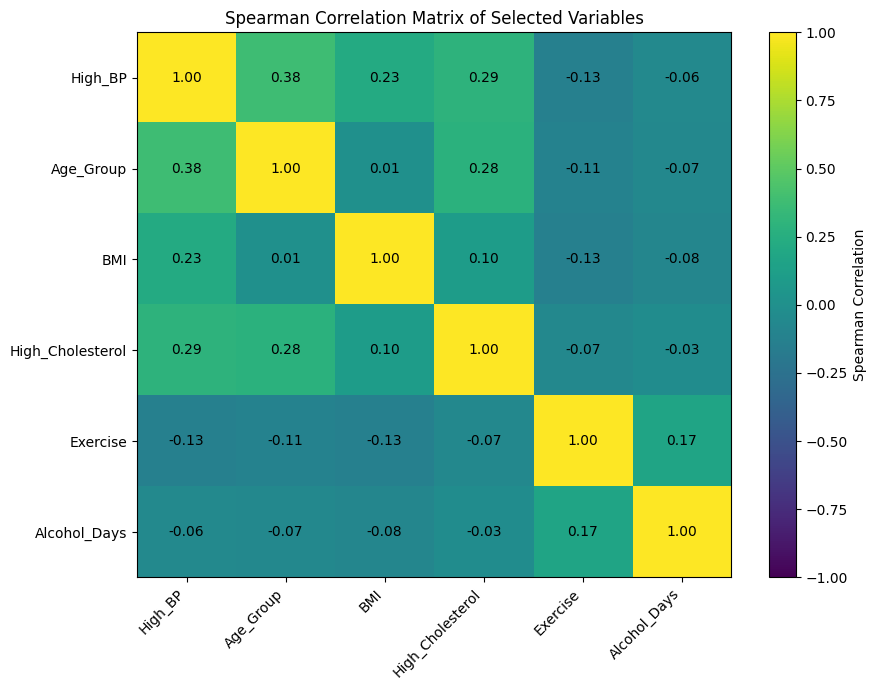

In [ ]:
# ---------------------------------------------------------
# EDA VISUALIZATION 7: Spearman Correlation Analysis
# ---------------------------------------------------------

correlation_matrix = correlation_df.corr(
    method="spearman"
)


print("Spearman Correlation Matrix:")

display(
    correlation_matrix.round(3)
)


# ---------------------------------------------------------
# Visualisation
# ---------------------------------------------------------

plt.figure(figsize=(9, 7))

plt.imshow(
    correlation_matrix,
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(
    label="Spearman Correlation"
)

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)


# Add correlation values inside cells
for row in range(len(correlation_matrix.columns)):

    for column in range(len(correlation_matrix.columns)):

        plt.text(
            column,
            row,
            f"{correlation_matrix.iloc[row, column]:.2f}",
            ha="center",
            va="center"
        )


plt.title(
    "Spearman Correlation Matrix of Selected Variables"
)

plt.tight_layout()

plt.show()

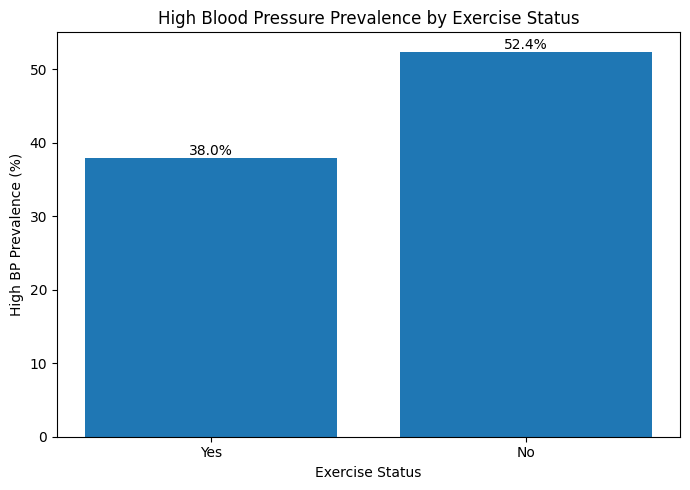

In [ ]:
# ---------------------------------------------------------
# EDA VISUALIZATION 6: High BP Prevalence by Exercise Status
# ---------------------------------------------------------

import matplotlib.pyplot as plt


# Calculate the percentage of respondents with High BP
# within each exercise-status category.

exercise_bp_prevalence = (
    prepared_df
    .groupby("exercise", observed=True)["high_bp"]
    .mean()
    * 100
)


# Arrange categories in a logical order.

exercise_order = [
    "Yes",
    "No"
]

exercise_bp_prevalence = (
    exercise_bp_prevalence
    .reindex(exercise_order)
)


# ---------------------------------------------------------
# Create bar chart
# ---------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(
    exercise_bp_prevalence.index,
    exercise_bp_prevalence.values
)

plt.title("High Blood Pressure Prevalence by Exercise Status")

plt.xlabel("Exercise Status")

plt.ylabel("High BP Prevalence (%)")


# Add percentage labels above each bar.

for index, value in enumerate(exercise_bp_prevalence.values):

    plt.text(
        index,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )


plt.tight_layout()

plt.show()

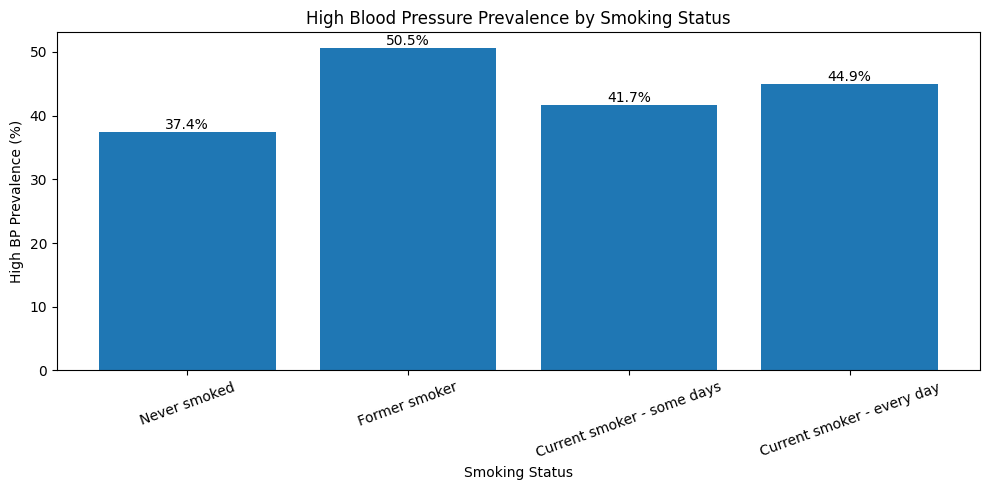

In [ ]:
# ---------------------------------------------------------
# EDA VISUALIZATION 5: High BP Prevalence by Smoking Status
# ---------------------------------------------------------

import matplotlib.pyplot as plt


# Calculate the percentage of respondents with High BP
# within each smoking-status category.

smoking_bp_prevalence = (
    prepared_df
    .groupby("smoking_status", observed=True)["high_bp"]
    .mean()
    * 100
)


# Arrange smoking categories in a meaningful order.

smoking_order = [
    "Never smoked",
    "Former smoker",
    "Current smoker - some days",
    "Current smoker - every day"
]

smoking_bp_prevalence = (
    smoking_bp_prevalence
    .reindex(smoking_order)
)


# ---------------------------------------------------------
# Create bar chart
# ---------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    smoking_bp_prevalence.index,
    smoking_bp_prevalence.values
)

plt.title("High Blood Pressure Prevalence by Smoking Status")

plt.xlabel("Smoking Status")

plt.ylabel("High BP Prevalence (%)")


# Rotate category labels for readability.

plt.xticks(rotation=20)


# Add percentage labels above each bar.

for index, value in enumerate(smoking_bp_prevalence.values):

    plt.text(
        index,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )


plt.tight_layout()

plt.show()

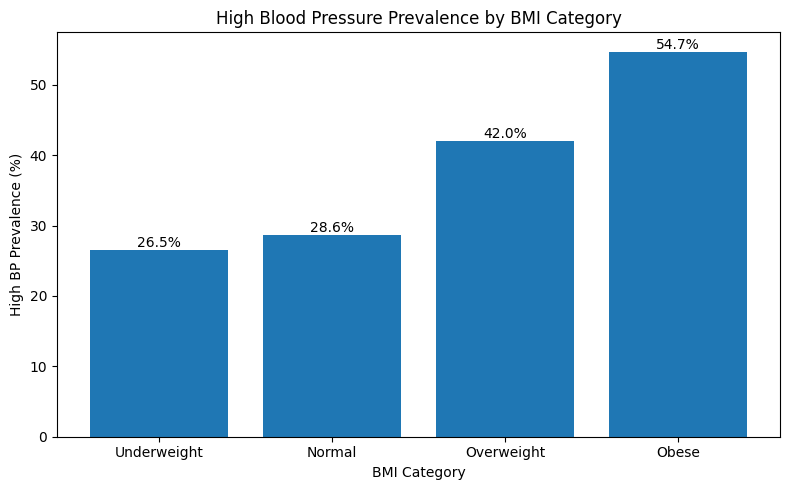

In [ ]:
# ---------------------------------------------------------
# EDA VISUALIZATION 4: High BP Prevalence by BMI Category
# ---------------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt


# ---------------------------------------------------------
# 1. Create BMI categories
# ---------------------------------------------------------

# Standard BMI grouping:
# Underweight : BMI < 18.5
# Normal      : 18.5 - 24.9
# Overweight  : 25.0 - 29.9
# Obese       : BMI >= 30.0

prepared_df["bmi_category"] = pd.cut(
    prepared_df["bmi"],
    bins=[
        0,
        18.5,
        25,
        30,
        float("inf")
    ],
    labels=[
        "Underweight",
        "Normal",
        "Overweight",
        "Obese"
    ],
    right=False
)


# ---------------------------------------------------------
# 2. Calculate High BP prevalence for each BMI category
# ---------------------------------------------------------

bmi_bp_prevalence = (
    prepared_df
    .groupby("bmi_category", observed=True)["high_bp"]
    .mean()
    * 100
)


# Arrange categories in logical order.

bmi_order = [
    "Underweight",
    "Normal",
    "Overweight",
    "Obese"
]

bmi_bp_prevalence = (
    bmi_bp_prevalence
    .reindex(bmi_order)
)


# ---------------------------------------------------------
# 3. Create bar chart
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    bmi_bp_prevalence.index,
    bmi_bp_prevalence.values
)

plt.title("High Blood Pressure Prevalence by BMI Category")

plt.xlabel("BMI Category")

plt.ylabel("High BP Prevalence (%)")


# Add percentage labels above bars.

for index, value in enumerate(bmi_bp_prevalence.values):

    plt.text(
        index,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )


plt.tight_layout()

plt.show()

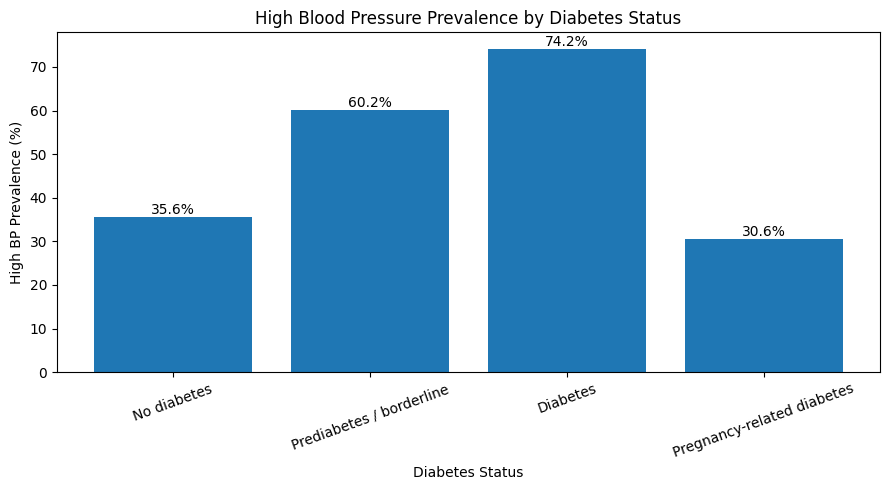

In [ ]:
# ---------------------------------------------------------
# EDA VISUALIZATION 3: High BP Prevalence by Diabetes Status
# ---------------------------------------------------------

import matplotlib.pyplot as plt


# Calculate the percentage of respondents with High BP
# within each diabetes-status category.
#
# high_bp:
# 0 = No High BP
# 1 = High BP
#
# Therefore, the mean gives the proportion with High BP.

diabetes_bp_prevalence = (
    prepared_df
    .groupby("diabetes_status", observed=True)["high_bp"]
    .mean()
    * 100
)


# Arrange the categories in a logical order.

diabetes_order = [
    "No diabetes",
    "Prediabetes / borderline",
    "Diabetes",
    "Pregnancy-related diabetes"
]

diabetes_bp_prevalence = (
    diabetes_bp_prevalence
    .reindex(diabetes_order)
)


# ---------------------------------------------------------
# Create the bar chart
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    diabetes_bp_prevalence.index,
    diabetes_bp_prevalence.values
)

plt.title("High Blood Pressure Prevalence by Diabetes Status")

plt.xlabel("Diabetes Status")

plt.ylabel("High BP Prevalence (%)")


# Rotate labels slightly for readability.

plt.xticks(rotation=20)


# Add percentage labels above each bar.

for index, value in enumerate(diabetes_bp_prevalence.values):

    plt.text(
        index,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )


plt.tight_layout()

plt.show()

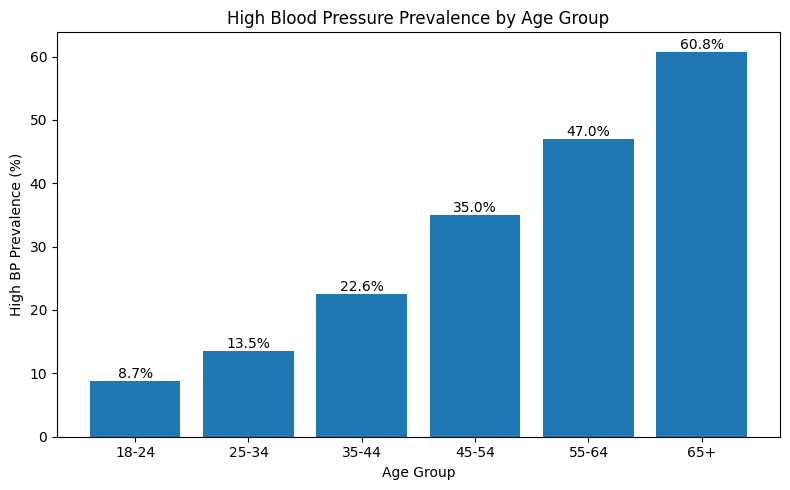

In [ ]:
# ---------------------------------------------------------
# EDA VISUALIZATION 2: High BP Prevalence by Age Group
# ---------------------------------------------------------

import matplotlib.pyplot as plt


# Calculate the percentage of respondents with High BP
# within each age group.
#
# Since high_bp is coded as:
# 0 = No High BP
# 1 = High BP
#
# the mean of high_bp gives the proportion with High BP.

age_bp_prevalence = (
    prepared_df
    .groupby("age_group", observed=True)["high_bp"]
    .mean()
    * 100
)


# Arrange age groups in logical order.

age_order = [
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]

age_bp_prevalence = (
    age_bp_prevalence
    .reindex(age_order)
)


# ---------------------------------------------------------
# Create the bar chart
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    age_bp_prevalence.index,
    age_bp_prevalence.values
)

plt.title("High Blood Pressure Prevalence by Age Group")

plt.xlabel("Age Group")

plt.ylabel("High BP Prevalence (%)")


# Add percentage labels above each bar.

for index, value in enumerate(age_bp_prevalence.values):

    plt.text(
        index,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )


plt.tight_layout()

plt.show()

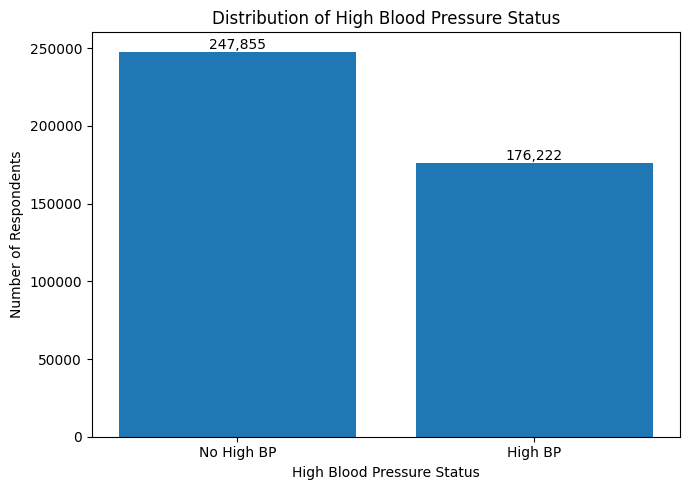

In [ ]:
# ---------------------------------------------------------
# EDA VISUALIZATION 1: High Blood Pressure Class Distribution
# ---------------------------------------------------------

import matplotlib.pyplot as plt

bp_counts = (
    prepared_df["high_bp"]
    .value_counts()
    .sort_index()
)

class_labels = [
    "No High BP",
    "High BP"
]

plt.figure(figsize=(7, 5))

plt.bar(
    class_labels,
    bp_counts.values
)

plt.title("Distribution of High Blood Pressure Status")
plt.xlabel("High Blood Pressure Status")
plt.ylabel("Number of Respondents")

for index, value in enumerate(bp_counts.values):
    plt.text(
        index,
        value,
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [ ]:
# ---------------------------------------------------------
# QUICK RECOVERY: Recreate prepared_df
# ---------------------------------------------------------

import pandas as pd
import numpy as np


# Load dataset again if needed.

file_path = "/content/drive/MyDrive/Data Science/BRFSS2023.csv"

df = pd.read_csv(
    file_path,
    low_memory=False
)


# ---------------------------------------------------------
# Recreate cleaned High Blood Pressure target
# ---------------------------------------------------------

bp_df = df[
    df["bphigh6"].isin([1.0, 3.0])
].copy()

bp_df["high_bp"] = bp_df["bphigh6"].map({
    1.0: 1,
    3.0: 0
})


# ---------------------------------------------------------
# Recreate candidate feature list
# ---------------------------------------------------------

available_features = [
    "_age_g",
    "_sex",
    "marital",
    "educa",
    "income3",
    "employ1",
    "_bmi5",
    "toldhi3",
    "diabete4",
    "exerany2",
    "_smoker3",
    "alcday4",
    "checkup1"
]


# ---------------------------------------------------------
# Create model dataframe
# ---------------------------------------------------------

model_df = bp_df[
    available_features + ["high_bp"]
].copy()


# Convert special BRFSS codes into missing values.

special_missing_codes = {
    "marital": [9.0],
    "educa": [9.0],
    "income3": [77.0, 99.0],
    "employ1": [9.0],
    "toldhi3": [7.0, 9.0],
    "diabete4": [7.0, 9.0],
    "exerany2": [7.0, 9.0],
    "_smoker3": [9],
    "checkup1": [7.0, 9.0],
    "alcday4": [777.0, 999.0]
}

for column, invalid_values in special_missing_codes.items():
    model_df[column] = model_df[column].replace(
        invalid_values,
        np.nan
    )


# ---------------------------------------------------------
# Recreate transformed dataframe
# ---------------------------------------------------------

prepared_df = model_df.copy()

prepared_df["bmi"] = prepared_df["_bmi5"] / 100

prepared_df["sex"] = prepared_df["_sex"].map({
    1: "Male",
    2: "Female"
})

prepared_df["high_cholesterol"] = prepared_df["toldhi3"].map({
    1.0: "Yes",
    2.0: "No"
})

prepared_df["diabetes_status"] = prepared_df["diabete4"].map({
    1.0: "Diabetes",
    2.0: "Pregnancy-related diabetes",
    3.0: "No diabetes",
    4.0: "Prediabetes / borderline"
})

prepared_df["exercise"] = prepared_df["exerany2"].map({
    1.0: "Yes",
    2.0: "No"
})

prepared_df["smoking_status"] = prepared_df["_smoker3"].map({
    1: "Current smoker - every day",
    2: "Current smoker - some days",
    3: "Former smoker",
    4: "Never smoked"
})

prepared_df["age_group"] = prepared_df["_age_g"].map({
    1: "18-24",
    2: "25-34",
    3: "35-44",
    4: "45-54",
    5: "55-64",
    6: "65+"
})

prepared_df["marital_status"] = prepared_df["marital"].map({
    1.0: "Married",
    2.0: "Divorced",
    3.0: "Widowed",
    4.0: "Separated",
    5.0: "Never married",
    6.0: "Unmarried couple"
})

prepared_df["education"] = prepared_df["educa"].map({
    1.0: "Never attended school",
    2.0: "Grades 1-8",
    3.0: "Grades 9-11",
    4.0: "High school graduate",
    5.0: "Some college / technical school",
    6.0: "College graduate"
})

prepared_df["employment"] = prepared_df["employ1"].map({
    1.0: "Employed for wages",
    2.0: "Self-employed",
    3.0: "Out of work > 1 year",
    4.0: "Out of work < 1 year",
    5.0: "Homemaker",
    6.0: "Student",
    7.0: "Retired",
    8.0: "Unable to work"
})

prepared_df["income_group"] = prepared_df["income3"].map({
    1.0: "< $10,000",
    2.0: "$10,000-$14,999",
    3.0: "$15,000-$19,999",
    4.0: "$20,000-$24,999",
    5.0: "$25,000-$34,999",
    6.0: "$35,000-$49,999",
    7.0: "$50,000-$74,999",
    8.0: "$75,000-$99,999",
    9.0: "$100,000-$149,999",
    10.0: "$150,000-$199,999",
    11.0: "$200,000+"
})


def convert_alcohol_days(value):

    if pd.isna(value):
        return np.nan

    if value == 888:
        return 0

    if 101 <= value <= 107:
        return (value - 100) * 4.345

    if 201 <= value <= 230:
        return value - 200

    return np.nan


prepared_df["alcohol_days_month"] = (
    prepared_df["alcday4"]
    .apply(convert_alcohol_days)
)

prepared_df["routine_checkup"] = prepared_df["checkup1"].map({
    1.0: "Within past year",
    2.0: "Within past 2 years",
    3.0: "Within past 5 years",
    4.0: "5 or more years ago",
    8.0: "Never"
})


# Confirm everything is recreated.

print("prepared_df recreated successfully.")
print("Shape:", prepared_df.shape)
print(prepared_df["high_bp"].value_counts())

prepared_df recreated successfully.
Shape: (424077, 27)
high_bp
0    247855
1    176222
Name: count, dtype: int64


In [ ]:
# ---------------------------------------------------------
# EDA VISUALIZATION 1: High Blood Pressure Class Distribution
# ---------------------------------------------------------

import matplotlib.pyplot as plt


# Count the number of respondents in each target class.
#
# 0 = No High Blood Pressure
# 1 = High Blood Pressure

bp_counts = (
    prepared_df["high_bp"]
    .value_counts()
    .sort_index()
)


# Create readable labels for the chart.

class_labels = [
    "No High BP",
    "High BP"
]


# ---------------------------------------------------------
# Create bar chart
# ---------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(
    class_labels,
    bp_counts.values
)


# Add title and axis labels.

plt.title("Distribution of High Blood Pressure Status")

plt.xlabel("High Blood Pressure Status")

plt.ylabel("Number of Respondents")


# ---------------------------------------------------------
# Add exact counts above the bars
# ---------------------------------------------------------

for index, value in enumerate(bp_counts.values):

    plt.text(
        index,
        value,
        f"{value:,}",
        ha="center",
        va="bottom"
    )


plt.tight_layout()

plt.show()

In [ ]:
# ---------------------------------------------------------
# STEP 14.1: Visualise Confusion Matrices
# ---------------------------------------------------------

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


# Random Forest confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=[
        "No High BP",
        "High BP"
    ]
)

plt.title("Random Forest Confusion Matrix")

plt.tight_layout()

plt.show()


# XGBoost confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb,
    display_labels=[
        "No High BP",
        "High BP"
    ]
)

plt.title("XGBoost Confusion Matrix")

plt.tight_layout()

plt.show()

In [ ]:
ablation_results = pd.DataFrame(

    [
        result_A,
        result_B,
        result_C
    ],

    index=[

        "Demographic / Socioeconomic",

        "Demographic + Lifestyle",

        "All Features"
    ]
)


print(
    "Feature Ablation Results:"
)


display(
    ablation_results.round(4)
)

Feature Ablation Results:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Demographic / Socioeconomic,0.6779,0.6096,0.6251,0.6173,0.7362
Demographic + Lifestyle,0.7037,0.6417,0.6498,0.6457,0.7702
All Features,0.7280,0.6768,0.6609,0.6688,0.7999


In [ ]:
result_A = evaluate_feature_set(

    model_A,

    X_test[
        demographic_features
    ],

    y_test
)


result_B = evaluate_feature_set(

    model_B,

    X_test[
        demographic_lifestyle_features
    ],

    y_test
)


result_C = evaluate_feature_set(

    model_C,

    X_test[
        all_feature_set
    ],

    y_test
)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


def evaluate_feature_set(
    model,
    test_X,
    test_y
):

    predictions = model.predict(
        test_X
    )


    probabilities = (
        model.predict_proba(
            test_X
        )[:, 1]
    )


    return {

        "Accuracy":
            accuracy_score(
                test_y,
                predictions
            ),

        "Precision":
            precision_score(
                test_y,
                predictions
            ),

        "Recall":
            recall_score(
                test_y,
                predictions
            ),

        "F1-Score":
            f1_score(
                test_y,
                predictions
            ),

        "ROC-AUC":
            roc_auc_score(
                test_y,
                probabilities
            )
    }

In [ ]:
model_A = build_ablation_pipeline(
    demographic_features
)


model_B = build_ablation_pipeline(
    demographic_lifestyle_features
)


model_C = build_ablation_pipeline(
    all_feature_set
)


print("Training Model A...")

model_A.fit(

    X_ablation_train[
        demographic_features
    ],

    y_ablation_train
)


print("Training Model B...")

model_B.fit(

    X_ablation_train[
        demographic_lifestyle_features
    ],

    y_ablation_train
)


print("Training Model C...")

model_C.fit(

    X_ablation_train[
        all_feature_set
    ],

    y_ablation_train
)


print(
    "Feature Ablation Training Complete."
)

Training Model A...
Training Model B...
Training Model C...
Feature Ablation Training Complete.


In [ ]:
from sklearn.pipeline import Pipeline

from sklearn.compose import (
    ColumnTransformer
)

from sklearn.impute import (
    SimpleImputer
)

from sklearn.preprocessing import (
    OneHotEncoder
)

from xgboost import (
    XGBClassifier
)


def build_ablation_pipeline(
    features
):

    # Numerical features available
    # in the selected set.

    numerical = [

        column

        for column in features

        if column in [

            "bmi",
            "alcohol_days_month"
        ]
    ]


    # Remaining variables are categorical.

    categorical = [

        column

        for column in features

        if column not in numerical
    ]


    numerical_pipeline = Pipeline(
        steps=[

            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            )
        ]
    )


    categorical_pipeline = Pipeline(
        steps=[

            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),

            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore"
                )
            )
        ]
    )


    experiment_preprocessor = (
        ColumnTransformer(
            transformers=[

                (
                    "num",
                    numerical_pipeline,
                    numerical
                ),

                (
                    "cat",
                    categorical_pipeline,
                    categorical
                )
            ]
        )
    )


    experiment_model = XGBClassifier(

        n_estimators=200,

        max_depth=6,

        learning_rate=0.1,

        subsample=0.8,

        colsample_bytree=0.8,

        eval_metric="logloss",

        random_state=42,

        n_jobs=-1
    )


    return Pipeline(
        steps=[

            (
                "preprocessor",
                experiment_preprocessor
            ),

            (
                "classifier",
                experiment_model
            )
        ]
    )

In [ ]:
print(
    "Model A Features:",
    len(demographic_features)
)

print(
    "Model B Features:",
    len(demographic_lifestyle_features)
)

print(
    "Model C Features:",
    len(all_feature_set)
)

Model A Features: 6
Model B Features: 10
Model C Features: 13


In [ ]:
all_feature_set = (
    final_features.copy()
)

In [ ]:
demographic_lifestyle_features = (

    demographic_features

    + [

        "bmi",
        "exercise",
        "smoking_status",
        "alcohol_days_month"
    ]
)

In [ ]:
demographic_features = [

    "age_group",
    "sex",
    "marital_status",
    "education",
    "employment",
    "income_group"
]

In [ ]:
# ---------------------------------------------------------
# STEP 14.5: Feature Ablation Experiment
# ---------------------------------------------------------

from sklearn.model_selection import (
    train_test_split
)


X_ablation_train, _, y_ablation_train, _ = (
    train_test_split(
        X_train,
        y_train,
        train_size=100000,
        random_state=42,
        stratify=y_train
    )
)


print(
    "Ablation Training Sample:",
    X_ablation_train.shape
)


print(
    "\nTarget Distribution:"
)

print(
    (
        y_ablation_train
        .value_counts(normalize=True)
        * 100
    ).round(2)
)

Ablation Training Sample: (100000, 13)

Target Distribution:
high_bp
0    58.45
1    41.55
Name: proportion, dtype: float64


In [ ]:
age_performance = subgroup_performance(
    evaluation_df,
    "age_group"
)


age_order = [
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]


age_performance["Group"] = pd.Categorical(
    age_performance["Group"],
    categories=age_order,
    ordered=True
)


age_performance = (
    age_performance
    .sort_values("Group")
)


print(
    "XGBoost Performance by Age Group:"
)

display(
    age_performance.round(4)
)

XGBoost Performance by Age Group:


,Group,Sample Size,Accuracy,Precision,Recall,F1-Score
0,18-24,5170,0.9155,0.4667,0.0322,0.0602
1,25-34,8765,0.8686,0.4936,0.0670,0.1179
2,35-44,10870,0.7969,0.6253,0.1938,0.2959
3,45-54,12120,0.7085,0.6394,0.4100,0.4996
4,55-64,15200,0.6816,0.6700,0.6376,0.6534
5,65+,32691,0.6710,0.6894,0.8319,0.7540


In [ ]:
sex_performance = subgroup_performance(
    evaluation_df,
    "sex"
)


print(
    "XGBoost Performance by Sex:"
)

display(
    sex_performance.round(4)
)

XGBoost Performance by Sex:


,Group,Sample Size,Accuracy,Precision,Recall,F1-Score
0,Female,44748,0.7356,0.6758,0.6384,0.6566
1,Male,40068,0.7232,0.6821,0.6875,0.6848


In [ ]:
def subgroup_performance(
    dataframe,
    group_variable
):

    results = []


    for group_name, group_data in dataframe.groupby(
        group_variable,
        observed=True
    ):

        actual = group_data["Actual"]

        predicted = group_data["Predicted"]


        results.append({

            "Group":
                group_name,

            "Sample Size":
                len(group_data),

            "Accuracy":
                accuracy_score(
                    actual,
                    predicted
                ),

            "Precision":
                precision_score(
                    actual,
                    predicted,
                    zero_division=0
                ),

            "Recall":
                recall_score(
                    actual,
                    predicted,
                    zero_division=0
                ),

            "F1-Score":
                f1_score(
                    actual,
                    predicted,
                    zero_division=0
                )
        })


    return pd.DataFrame(
        results
    )

In [ ]:
# ---------------------------------------------------------
# STEP 14.4: XGBoost Subgroup Performance Analysis
# ---------------------------------------------------------

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# Copy test predictor data.
evaluation_df = X_test.copy()


# Add actual labels.
evaluation_df["Actual"] = y_test


# Add XGBoost predictions with correct index.
evaluation_df["Predicted"] = pd.Series(
    y_pred_xgb,
    index=X_test.index
)


print(
    "Evaluation dataset shape:",
    evaluation_df.shape
)

Evaluation dataset shape: (84816, 15)


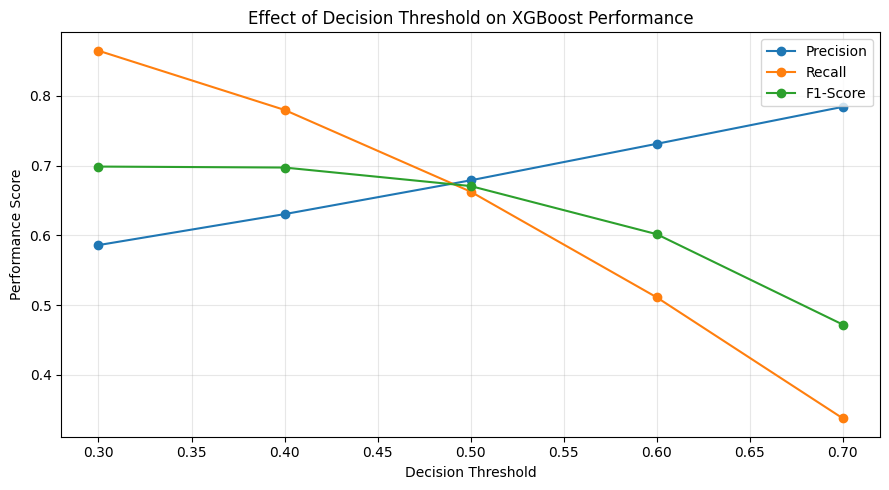

In [ ]:
plt.figure(figsize=(9, 5))


plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)


plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)


plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-Score"],
    marker="o",
    label="F1-Score"
)


plt.xlabel(
    "Decision Threshold"
)

plt.ylabel(
    "Performance Score"
)

plt.title(
    "Effect of Decision Threshold on XGBoost Performance"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [ ]:
# ---------------------------------------------------------
# STEP 14.3: XGBoost Decision Threshold Analysis
# ---------------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_values = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in threshold_values:

    threshold_predictions = (
        y_prob_xgb >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        threshold_predictions
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_test,
            threshold_predictions
        ),
        "Precision": precision_score(
            y_test,
            threshold_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            threshold_predictions,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test,
            threshold_predictions,
            zero_division=0
        ),
        "False Negatives": fn,
        "False Positives": fp
    })

threshold_df = pd.DataFrame(
    threshold_results
)

display(
    threshold_df.round(4)
)

,Threshold,Accuracy,Precision,Recall,F1-Score,False Negatives,False Positives
0,0.3,0.6901,0.5862,0.8649,0.6988,4762,21519
1,0.4,0.7187,0.6306,0.7800,0.6974,7754,16105
2,0.5,0.7297,0.6791,0.6628,0.6708,11884,11041
3,0.6,0.7189,0.7314,0.5113,0.6018,17225,6618
4,0.7,0.6862,0.7844,0.3378,0.4722,23340,3272


In [ ]:
# =========================================================
# COMPLETE RECOVERY FOR XGBOOST + THRESHOLD ANALYSIS
# =========================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from xgboost import XGBClassifier


# ---------------------------------------------------------
# 1. Load original BRFSS 2023 dataset
# ---------------------------------------------------------

file_path = "/content/drive/MyDrive/Data Science/BRFSS2023.csv"

df = pd.read_csv(
    file_path,
    low_memory=False
)

print("Original dataset:", df.shape)


# ---------------------------------------------------------
# 2. Recreate strict High Blood Pressure target
# ---------------------------------------------------------
# Only definite:
# 1 = Yes
# 3 = No
#
# Pregnancy-related, borderline, unknown and refused
# responses are excluded.

bp_df = df[
    df["bphigh6"].isin([1.0, 3.0])
].copy()

bp_df["high_bp"] = bp_df["bphigh6"].map({
    1.0: 1,
    3.0: 0
})

print("Valid High BP records:", len(bp_df))


# ---------------------------------------------------------
# 3. Select the same 13 original predictors
# ---------------------------------------------------------

raw_features = [
    "_age_g",
    "_sex",
    "marital",
    "educa",
    "income3",
    "employ1",
    "_bmi5",
    "toldhi3",
    "diabete4",
    "exerany2",
    "_smoker3",
    "alcday4",
    "checkup1"
]

model_df = bp_df[
    raw_features + ["high_bp"]
].copy()


# ---------------------------------------------------------
# 4. Convert BRFSS special response codes to NaN
# ---------------------------------------------------------

special_missing_codes = {

    "marital": [9.0],

    "educa": [9.0],

    "income3": [77.0, 99.0],

    "employ1": [9.0],

    "toldhi3": [7.0, 9.0],

    "diabete4": [7.0, 9.0],

    "exerany2": [7.0, 9.0],

    "_smoker3": [9],

    "alcday4": [777.0, 999.0],

    "checkup1": [7.0, 9.0]
}


for column, codes in special_missing_codes.items():

    model_df[column] = (
        model_df[column]
        .replace(codes, np.nan)
    )


# ---------------------------------------------------------
# 5. Recreate transformed predictor variables
# ---------------------------------------------------------

prepared_df = model_df.copy()


# BMI
prepared_df["bmi"] = (
    prepared_df["_bmi5"] / 100
)


# Age
prepared_df["age_group"] = prepared_df["_age_g"].map({

    1: "18-24",
    2: "25-34",
    3: "35-44",
    4: "45-54",
    5: "55-64",
    6: "65+"
})


# Sex
prepared_df["sex"] = prepared_df["_sex"].map({

    1: "Male",
    2: "Female"
})


# Marital status
prepared_df["marital_status"] = prepared_df["marital"].map({

    1.0: "Married",
    2.0: "Divorced",
    3.0: "Widowed",
    4.0: "Separated",
    5.0: "Never married",
    6.0: "Unmarried couple"
})


# Education
prepared_df["education"] = prepared_df["educa"].map({

    1.0: "Never attended school",
    2.0: "Grades 1-8",
    3.0: "Grades 9-11",
    4.0: "High school graduate",
    5.0: "Some college / technical school",
    6.0: "College graduate"
})


# Employment
prepared_df["employment"] = prepared_df["employ1"].map({

    1.0: "Employed for wages",
    2.0: "Self-employed",
    3.0: "Out of work > 1 year",
    4.0: "Out of work < 1 year",
    5.0: "Homemaker",
    6.0: "Student",
    7.0: "Retired",
    8.0: "Unable to work"
})


# Income
prepared_df["income_group"] = prepared_df["income3"].map({

    1.0: "< $10,000",
    2.0: "$10,000-$14,999",
    3.0: "$15,000-$19,999",
    4.0: "$20,000-$24,999",
    5.0: "$25,000-$34,999",
    6.0: "$35,000-$49,999",
    7.0: "$50,000-$74,999",
    8.0: "$75,000-$99,999",
    9.0: "$100,000-$149,999",
    10.0: "$150,000-$199,999",
    11.0: "$200,000+"
})


# High cholesterol
prepared_df["high_cholesterol"] = prepared_df["toldhi3"].map({

    1.0: "Yes",
    2.0: "No"
})


# Diabetes
prepared_df["diabetes_status"] = prepared_df["diabete4"].map({

    1.0: "Diabetes",
    2.0: "Pregnancy-related diabetes",
    3.0: "No diabetes",
    4.0: "Prediabetes / borderline"
})


# Exercise
prepared_df["exercise"] = prepared_df["exerany2"].map({

    1.0: "Yes",
    2.0: "No"
})


# Smoking
prepared_df["smoking_status"] = prepared_df["_smoker3"].map({

    1: "Current smoker - every day",
    2: "Current smoker - some days",
    3: "Former smoker",
    4: "Never smoked"
})


# Alcohol conversion
def convert_alcohol_days(value):

    if pd.isna(value):
        return np.nan

    if value == 888:
        return 0

    if 101 <= value <= 107:
        return (value - 100) * 4.345

    if 201 <= value <= 230:
        return value - 200

    return np.nan


prepared_df["alcohol_days_month"] = (
    prepared_df["alcday4"]
    .apply(convert_alcohol_days)
)


# Routine check-up
prepared_df["routine_checkup"] = prepared_df["checkup1"].map({

    1.0: "Within past year",
    2.0: "Within past 2 years",
    3.0: "Within past 5 years",
    4.0: "5 or more years ago",
    8.0: "Never"
})


# ---------------------------------------------------------
# 6. Define the same final 13 predictors
# ---------------------------------------------------------

final_features = [

    "age_group",
    "sex",
    "marital_status",

    "education",
    "employment",
    "income_group",

    "bmi",
    "high_cholesterol",
    "diabetes_status",

    "exercise",
    "smoking_status",
    "alcohol_days_month",

    "routine_checkup"
]


X = prepared_df[
    final_features
].copy()

y = prepared_df[
    "high_bp"
].copy()


print("X shape:", X.shape)
print("y shape:", y.shape)


# ---------------------------------------------------------
# 7. Define numerical and categorical features
# ---------------------------------------------------------

numerical_features = [

    "bmi",
    "alcohol_days_month"
]


categorical_features_final = [

    "age_group",
    "sex",
    "marital_status",
    "education",
    "employment",
    "income_group",
    "high_cholesterol",
    "diabetes_status",
    "exercise",
    "smoking_status",
    "routine_checkup"
]


# ---------------------------------------------------------
# 8. Same stratified 80/20 split
# ---------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)


print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)


# ---------------------------------------------------------
# 9. Recreate preprocessing pipeline
# ---------------------------------------------------------

numerical_pipeline = Pipeline(

    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]
)


categorical_pipeline = Pipeline(

    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),

        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


preprocessor = ColumnTransformer(

    transformers=[

        (
            "num",
            numerical_pipeline,
            numerical_features
        ),

        (
            "cat",
            categorical_pipeline,
            categorical_features_final
        )
    ]
)


# ---------------------------------------------------------
# 10. Recreate the SAME XGBoost model
# ---------------------------------------------------------

xgb_model = Pipeline(

    steps=[

        (
            "preprocessor",
            preprocessor
        ),

        (
            "classifier",
            XGBClassifier(

                n_estimators=200,

                max_depth=6,

                learning_rate=0.1,

                subsample=0.8,

                colsample_bytree=0.8,

                eval_metric="logloss",

                random_state=42,

                n_jobs=-1
            )
        )
    ]
)


# ---------------------------------------------------------
# 11. Retrain XGBoost
# ---------------------------------------------------------

print("\nTraining XGBoost...")

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost training complete.")


# ---------------------------------------------------------
# 12. Recreate predictions and probabilities
# ---------------------------------------------------------

y_pred_xgb = xgb_model.predict(
    X_test
)

y_prob_xgb = xgb_model.predict_proba(
    X_test
)[:, 1]


print("\nRecovery completed successfully.")

print(
    "Number of test predictions:",
    len(y_pred_xgb)
)

print(
    "Number of probabilities:",
    len(y_prob_xgb)
)

Original dataset: (433323, 350)
Valid High BP records: 424077
X shape: (424077, 13)
y shape: (424077,)
Training data: (339261, 13)
Testing data : (84816, 13)

Training XGBoost...
XGBoost training complete.

Recovery completed successfully.
Number of test predictions: 84816
Number of probabilities: 84816


In [ ]:
print("xgb_model exists:", "xgb_model" in globals())
print("X_test exists:", "X_test" in globals())
print("y_test exists:", "y_test" in globals())

xgb_model exists: False
X_test exists: False
y_test exists: False


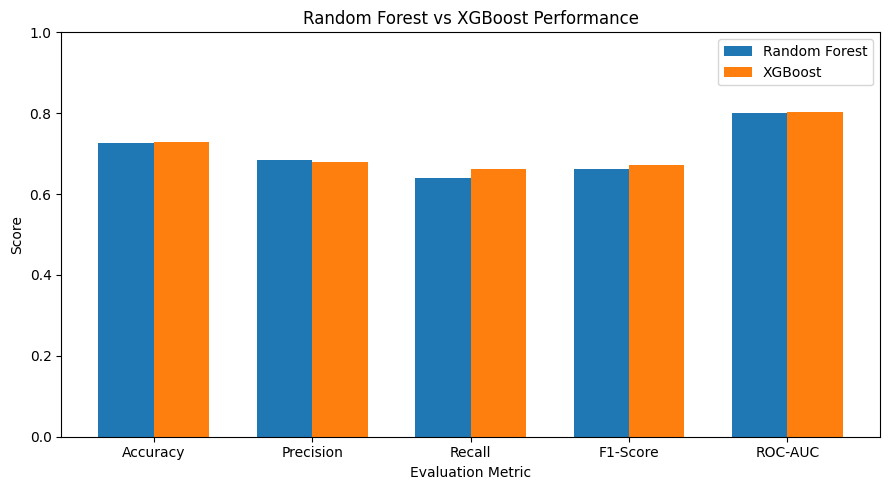

In [ ]:
# ---------------------------------------------------------
# STEP 14.2: Visualise Final Model Performance
# ---------------------------------------------------------

import matplotlib.pyplot as plt
import numpy as np


# Metrics that will be compared.

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]


# Random Forest results.

rf_scores = [
    0.7274,
    0.6836,
    0.6402,
    0.6612,
    0.7998
]


# XGBoost results.

xgb_scores = [
    0.7297,
    0.6791,
    0.6628,
    0.6708,
    0.8024
]


# Create positions for grouped bars.

x = np.arange(
    len(metrics)
)

width = 0.35


# Create chart.

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    x - width / 2,
    rf_scores,
    width,
    label="Random Forest"
)

plt.bar(
    x + width / 2,
    xgb_scores,
    width,
    label="XGBoost"
)


# Add labels.

plt.xlabel("Evaluation Metric")

plt.ylabel("Score")

plt.title(
    "Random Forest vs XGBoost Performance"
)

plt.xticks(
    x,
    metrics
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
# ---------------------------------------------------------
# STEP 14: Compare Final Models
# ---------------------------------------------------------

# Create a comparison table for the two final models:
# Random Forest and XGBoost.

model_comparison = pd.DataFrame({

    "Model": [
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        0.7274,
        0.7297
    ],

    "High BP Precision": [
        0.6836,
        0.6791
    ],

    "High BP Recall": [
        0.6402,
        0.6628
    ],

    "High BP F1-Score": [
        0.6612,
        0.6708
    ],

    "ROC-AUC": [
        0.7998,
        0.8024
    ]
})


print("Final Model Performance Comparison:")

display(model_comparison)

Final Model Performance Comparison:


,Model,Accuracy,High BP Precision,High BP Recall,High BP F1-Score,ROC-AUC
0,Random Forest,0.7274,0.6836,0.6402,0.6612,0.7998
1,XGBoost,0.7297,0.6791,0.6628,0.6708,0.8024


In [ ]:
# ---------------------------------------------------------
# STEP 13: Train XGBoost Model
# ---------------------------------------------------------

# Install xgboost if it is not already available.
!pip install -q xgboost


# Import XGBoost classifier.

from xgboost import XGBClassifier


# ---------------------------------------------------------
# Create XGBoost pipeline
# ---------------------------------------------------------

# The same preprocessing pipeline is used for fair comparison.

xgb_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            XGBClassifier(
                n_estimators=200,
                max_depth=6,
                learning_rate=0.1,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)


# ---------------------------------------------------------
# Train XGBoost
# ---------------------------------------------------------

xgb_model.fit(
    X_train,
    y_train
)


# ---------------------------------------------------------
# Generate predictions
# ---------------------------------------------------------

y_pred_xgb = xgb_model.predict(
    X_test
)

y_prob_xgb = xgb_model.predict_proba(
    X_test
)[:, 1]


# ---------------------------------------------------------
# Evaluate XGBoost
# ---------------------------------------------------------

print("XGBOOST RESULTS")
print("=" * 50)

print(
    "\nAccuracy:",
    round(
        accuracy_score(y_test, y_pred_xgb),
        4
    )
)

print(
    "\nROC-AUC:",
    round(
        roc_auc_score(y_test, y_prob_xgb),
        4
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_xgb,
        digits=4
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_test,
        y_pred_xgb
    )
)

NameError: name 'Pipeline' is not defined

In [ ]:
# ---------------------------------------------------------
# STEP 12: Train Random Forest Model
# ---------------------------------------------------------

from sklearn.ensemble import RandomForestClassifier


# ---------------------------------------------------------
# Create Random Forest pipeline
# ---------------------------------------------------------

# The same preprocessing pipeline is used so that
# Logistic Regression and Random Forest are compared fairly.
#
# Faster settings are used to keep training manageable
# in Google Colab.

random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)


# ---------------------------------------------------------
# Train Random Forest
# ---------------------------------------------------------

random_forest_model.fit(
    X_train,
    y_train
)


# ---------------------------------------------------------
# Generate predictions
# ---------------------------------------------------------

y_pred_rf = random_forest_model.predict(
    X_test
)


# Generate predicted probabilities for High BP class.

y_prob_rf = random_forest_model.predict_proba(
    X_test
)[:, 1]


# ---------------------------------------------------------
# Evaluate Random Forest
# ---------------------------------------------------------

print("RANDOM FOREST RESULTS")
print("=" * 50)


print(
    "\nAccuracy:",
    round(
        accuracy_score(
            y_test,
            y_pred_rf
        ),
        4
    )
)


print(
    "\nROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            y_prob_rf
        ),
        4
    )
)


print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_rf,
        digits=4
    )
)


print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_test,
        y_pred_rf
    )
)

In [ ]:
# ---------------------------------------------------------
# STEP 11: Train Logistic Regression Model
# ---------------------------------------------------------

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)


# ---------------------------------------------------------
# Create complete pipeline
# ---------------------------------------------------------

# This pipeline automatically:
# 1. Handles missing values
# 2. Encodes categorical variables
# 3. Trains Logistic Regression

logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)


# ---------------------------------------------------------
# Train the model
# ---------------------------------------------------------

logistic_model.fit(
    X_train,
    y_train
)


# ---------------------------------------------------------
# Generate predictions
# ---------------------------------------------------------

y_pred_logistic = logistic_model.predict(
    X_test
)


# Get probabilities for High Blood Pressure class.

y_prob_logistic = logistic_model.predict_proba(
    X_test
)[:, 1]


# ---------------------------------------------------------
# Evaluate the model
# ---------------------------------------------------------

print("LOGISTIC REGRESSION RESULTS")
print("=" * 50)


print(
    "\nAccuracy:",
    round(
        accuracy_score(
            y_test,
            y_pred_logistic
        ),
        4
    )
)


print(
    "\nROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            y_prob_logistic
        ),
        4
    )
)


print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_logistic,
        digits=4
    )
)


print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_test,
        y_pred_logistic
    )
)

In [ ]:
# ---------------------------------------------------------
# STEP 10: Split Data and Create Preprocessing Pipeline
# ---------------------------------------------------------

# Import required tools.

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


# ---------------------------------------------------------
# 1. Split the dataset into training and testing sets
# ---------------------------------------------------------

# 80% of records are used to train the models.
# 20% are reserved for evaluating model performance.
#
# stratify=y preserves the High BP / No High BP ratio
# in both the training and testing datasets.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# ---------------------------------------------------------
# 2. Numerical preprocessing
# ---------------------------------------------------------

# Missing numerical values are replaced using the median.

numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)


# ---------------------------------------------------------
# 3. Categorical preprocessing
# ---------------------------------------------------------

# Missing categorical values are replaced with the
# most frequently occurring category.
#
# One-hot encoding converts category names into numeric
# columns that machine-learning algorithms can use.

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)


# ---------------------------------------------------------
# 4. Combine both preprocessing methods
# ---------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_pipeline,
            numerical_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features_final
        )
    ]
)


# ---------------------------------------------------------
# 5. Display train/test sizes and class distribution
# ---------------------------------------------------------

print("Training predictor shape:", X_train.shape)
print("Test predictor shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Test target shape:", y_test.shape)

print("\nTraining target percentage:")
print(
    (
        y_train.value_counts(normalize=True)
        * 100
    ).round(2)
)

print("\nTest target percentage:")
print(
    (
        y_test.value_counts(normalize=True)
        * 100
    ).round(2)
)

Final Missing-Value Observation:
The final predictor set contained missing values in several variables, with household income showing the highest proportion at 19.88%, followed by high cholesterol at 12.55%, BMI at 9.26%, alcohol consumption at 6.88%, and smoking status at 5.28%. Since removing all incomplete records would substantially reduce the dataset, missing values will be handled through imputation within the preprocessing pipeline. Numerical variables will use median imputation, while categorical variables will use the most frequent category.

In [ ]:
# ---------------------------------------------------------
# STEP 9.2: Check Missing Values in Final Features
# ---------------------------------------------------------

final_missing_summary = pd.DataFrame({

    "Missing Values":
        X.isna().sum(),

    "Missing Percentage":
        (
            X.isna().mean()
            * 100
        ).round(2)
})


# Sort from highest missing percentage to lowest.

final_missing_summary = (
    final_missing_summary
    .sort_values(
        by="Missing Percentage",
        ascending=False
    )
)


print("Missing values in final model features:")

display(final_missing_summary)

In [ ]:
# ---------------------------------------------------------
# STEP 9.1: Separate Numerical and Categorical Features
# ---------------------------------------------------------

numerical_features = [
    "bmi",
    "alcohol_days_month"
]


categorical_features_final = [
    "age_group",
    "sex",
    "marital_status",
    "education",
    "employment",
    "income_group",
    "high_cholesterol",
    "diabetes_status",
    "exercise",
    "smoking_status",
    "routine_checkup"
]


print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features_final)

In [ ]:
# ---------------------------------------------------------
# STEP 9: Define Final Features for Machine Learning
# ---------------------------------------------------------

# Select the transformed predictor variables that will be used
# to train the High Blood Pressure classification models.

final_features = [

    # Demographic
    "age_group",
    "sex",
    "marital_status",

    # Socioeconomic
    "education",
    "employment",
    "income_group",

    # Health
    "bmi",
    "high_cholesterol",
    "diabetes_status",

    # Lifestyle
    "exercise",
    "smoking_status",
    "alcohol_days_month",

    # Healthcare
    "routine_checkup"
]


# Create predictor dataframe X.

X = prepared_df[
    final_features
].copy()


# Create target y.
# 0 = No High Blood Pressure
# 1 = High Blood Pressure

y = prepared_df[
    "high_bp"
].copy()


# Display the dataset sizes.

print("Predictor dataset shape:", X.shape)
print("Target shape:", y.shape)


# Display selected features.

print("\nFinal selected features:")

for feature in final_features:
    print("-", feature)

Remaining Feature Transformation Observation:
The remaining predictor variables were successfully transformed into interpretable categories suitable for analysis. Age, marital status, education, employment, income, and routine check-up variables were converted from numeric survey codes into meaningful labels. Alcohol consumption was also converted into an estimated number of drinking days per month. Some missing values remain, particularly in the income variable, because uncertain and refused responses were previously treated as missing values. These missing values will be handled during the preprocessing stage before model training.

In [ ]:
import matplotlib.pyplot as plt

# Display descriptive statistics for transformed BMI.

print("BMI Descriptive Statistics:")
print(
    prepared_df["bmi"]
    .describe()
)

# ---------------------------------------------------------
# Create BMI boxplot
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.boxplot(
    prepared_df["bmi"].dropna(),
    vert=False
)

plt.title(
    "Distribution of BMI and Potential Outliers"
)

plt.xlabel("BMI")

plt.tight_layout()

plt.show()

BMI Descriptive Statistics:


NameError: name 'prepared_df' is not defined

In [ ]:
# ---------------------------------------------------------
# STEP 8: Recode Remaining Predictor Variables
# ---------------------------------------------------------

# ---------------------------------------------------------
# 1. Recode age group
# ---------------------------------------------------------

prepared_df["age_group"] = prepared_df["_age_g"].map({
    1: "18-24",
    2: "25-34",
    3: "35-44",
    4: "45-54",
    5: "55-64",
    6: "65+"
})


# ---------------------------------------------------------
# 2. Recode marital status
# ---------------------------------------------------------

prepared_df["marital_status"] = prepared_df["marital"].map({
    1.0: "Married",
    2.0: "Divorced",
    3.0: "Widowed",
    4.0: "Separated",
    5.0: "Never married",
    6.0: "Unmarried couple"
})


# ---------------------------------------------------------
# 3. Recode education level
# ---------------------------------------------------------

prepared_df["education"] = prepared_df["educa"].map({
    1.0: "Never attended school",
    2.0: "Grades 1-8",
    3.0: "Grades 9-11",
    4.0: "High school graduate",
    5.0: "Some college / technical school",
    6.0: "College graduate"
})


# ---------------------------------------------------------
# 4. Recode employment status
# ---------------------------------------------------------

prepared_df["employment"] = prepared_df["employ1"].map({
    1.0: "Employed for wages",
    2.0: "Self-employed",
    3.0: "Out of work > 1 year",
    4.0: "Out of work < 1 year",
    5.0: "Homemaker",
    6.0: "Student",
    7.0: "Retired",
    8.0: "Unable to work"
})


# ---------------------------------------------------------
# 5. Recode income group
# ---------------------------------------------------------

prepared_df["income_group"] = prepared_df["income3"].map({
    1.0: "< $10,000",
    2.0: "$10,000-$14,999",
    3.0: "$15,000-$19,999",
    4.0: "$20,000-$24,999",
    5.0: "$25,000-$34,999",
    6.0: "$35,000-$49,999",
    7.0: "$50,000-$74,999",
    8.0: "$75,000-$99,999",
    9.0: "$100,000-$149,999",
    10.0: "$150,000-$199,999",
    11.0: "$200,000+"
})


# ---------------------------------------------------------
# 6. Convert alcohol consumption into estimated days/month
# ---------------------------------------------------------

# ALCDAY4 coding:
# 101-107 = number of drinking days per week
# 201-230 = number of drinking days in past 30 days
# 888 = no alcohol in past 30 days

def convert_alcohol_days(value):

    # Keep missing values as missing.
    if pd.isna(value):
        return np.nan

    # 888 = no drinking during the past 30 days.
    if value == 888:
        return 0

    # Weekly frequency.
    if 101 <= value <= 107:
        days_per_week = value - 100
        return days_per_week * 4.345

    # Monthly frequency.
    if 201 <= value <= 230:
        return value - 200

    # Unexpected values are treated as missing.
    return np.nan


prepared_df["alcohol_days_month"] = (
    prepared_df["alcday4"]
    .apply(convert_alcohol_days)
)


# ---------------------------------------------------------
# 7. Recode routine check-up
# ---------------------------------------------------------

prepared_df["routine_checkup"] = prepared_df["checkup1"].map({
    1.0: "Within past year",
    2.0: "Within past 2 years",
    3.0: "Within past 5 years",
    4.0: "5 or more years ago",
    8.0: "Never"
})


# ---------------------------------------------------------
# Preview transformed variables
# ---------------------------------------------------------

remaining_preview = [
    "age_group",
    "marital_status",
    "education",
    "employment",
    "income_group",
    "alcohol_days_month",
    "routine_checkup",
    "high_bp"
]

print("Preview of remaining transformed variables:")

display(
    prepared_df[remaining_preview].head(10)
)

Transformed Feature Observation:
The selected health and lifestyle variables were successfully transformed into more interpretable and analysis-ready formats. BMI was converted into standard BMI units, while coded variables such as sex, high cholesterol, diabetes status, exercise, and smoking status were mapped into meaningful categories. The preview confirms that these transformations were applied correctly while preserving the binary High Blood Pressure target.

In [ ]:
# ---------------------------------------------------------
# STEP 7: Recode and Transform Selected Predictor Variables
# ---------------------------------------------------------

# Create a new working dataframe from the cleaned model data.
prepared_df = model_df.copy()


# ---------------------------------------------------------
# 1. Convert BMI into standard BMI units
# ---------------------------------------------------------

# BRFSS stores BMI multiplied by 100.
# Example: 2847 = BMI 28.47

prepared_df["bmi"] = prepared_df["_bmi5"] / 100


# ---------------------------------------------------------
# 2. Recode sex
# ---------------------------------------------------------

prepared_df["sex"] = prepared_df["_sex"].map({
    1: "Male",
    2: "Female"
})


# ---------------------------------------------------------
# 3. Recode high cholesterol
# ---------------------------------------------------------

prepared_df["high_cholesterol"] = prepared_df["toldhi3"].map({
    1.0: "Yes",
    2.0: "No"
})


# ---------------------------------------------------------
# 4. Recode diabetes status
# ---------------------------------------------------------

prepared_df["diabetes_status"] = prepared_df["diabete4"].map({
    1.0: "Diabetes",
    2.0: "Pregnancy-related diabetes",
    3.0: "No diabetes",
    4.0: "Prediabetes / borderline"
})


# ---------------------------------------------------------
# 5. Recode exercise status
# ---------------------------------------------------------

prepared_df["exercise"] = prepared_df["exerany2"].map({
    1.0: "Yes",
    2.0: "No"
})


# ---------------------------------------------------------
# 6. Recode smoking status
# ---------------------------------------------------------

prepared_df["smoking_status"] = prepared_df["_smoker3"].map({
    1: "Current smoker - every day",
    2: "Current smoker - some days",
    3: "Former smoker",
    4: "Never smoked"
})


# ---------------------------------------------------------
# Preview transformed variables
# ---------------------------------------------------------

preview_columns = [
    "bmi",
    "sex",
    "high_cholesterol",
    "diabetes_status",
    "exercise",
    "smoking_status",
    "high_bp"
]

print("Preview of transformed variables:")

display(
    prepared_df[preview_columns].head(10)
)

Special-Code Cleaning Observation:
After converting non-informative BRFSS response codes into missing values, several predictors showed increased missingness. Household income (income3) had the highest missing percentage at 19.88%, followed by high cholesterol (toldhi3, 12.55%), BMI (_bmi5, 9.26%), alcohol consumption (alcday4, 6.88%), and smoking status (_smoker3, 5.28%). Since removing all incomplete records would result in substantial data loss, missing values will be handled later using suitable imputation methods within the preprocessing pipeline.

In [ ]:
# ---------------------------------------------------------
# STEP 6: Convert Special Survey Codes to Missing Values
# ---------------------------------------------------------

# Import NumPy so that special survey responses can be
# converted into standard missing values (NaN).

import numpy as np


# Create a separate working dataframe containing:
# - 13 selected predictors
# - binary High Blood Pressure target
#
# This keeps the original bp_df unchanged.

model_df = bp_df[
    available_features + ["high_bp"]
].copy()


# ---------------------------------------------------------
# Define non-informative BRFSS response codes
# ---------------------------------------------------------

special_missing_codes = {

    "marital": [9.0],

    "educa": [9.0],

    "income3": [77.0, 99.0],

    "employ1": [9.0],

    "toldhi3": [7.0, 9.0],

    "diabete4": [7.0, 9.0],

    "exerany2": [7.0, 9.0],

    "_smoker3": [9],

    "checkup1": [7.0, 9.0],

    "alcday4": [777.0, 999.0]
}


# ---------------------------------------------------------
# Replace special response codes with NaN
# ---------------------------------------------------------

for column, invalid_values in special_missing_codes.items():

    model_df[column] = model_df[column].replace(
        invalid_values,
        np.nan
    )


# ---------------------------------------------------------
# Check missing values after code cleaning
# ---------------------------------------------------------

missing_after_cleaning = pd.DataFrame({

    "Missing Values":
        model_df[available_features]
        .isna()
        .sum(),

    "Missing Percentage":
        (
            model_df[available_features]
            .isna()
            .mean()
            * 100
        ).round(2)
})


print("Missing values after special-code cleaning:")

display(missing_after_cleaning)

Raw Predictor Inspection Observation:
The predictor variables contained several special BRFSS survey codes in addition to normal categories. Codes such as 9, 77, 99, 777, and 999 represent uncertain or refused responses rather than meaningful predictor values. BMI also contained 9.26% conventional missing values, while alcohol consumption included special codes alongside valid weekly and monthly drinking-frequency codes. Therefore, these non-informative responses should be converted into missing values before further transformation.

In [ ]:
# ---------------------------------------------------------
# STEP 5.2: Inspect Alcohol Consumption Codes
# ---------------------------------------------------------

print("Alcohol consumption codes:")

print(
    bp_df["alcday4"]
    .value_counts(dropna=False)
    .sort_index()
)

In [ ]:
# ---------------------------------------------------------
# STEP 5.1: Inspect BMI
# ---------------------------------------------------------

print("BMI variable summary:")

print(
    bp_df["_bmi5"].describe()
)

bmi_missing = bp_df["_bmi5"].isna().sum()

bmi_missing_percentage = (
    bp_df["_bmi5"].isna().mean()
    * 100
)

print("\nMissing BMI values:", bmi_missing)

print(
    "Missing BMI percentage:",
    round(bmi_missing_percentage, 2),
    "%"
)

In [ ]:
# ---------------------------------------------------------
# STEP 5: Inspect Raw Values of Categorical Predictors
# ---------------------------------------------------------

# BRFSS survey variables may use special codes such as
# 7, 9, 77, or 99 for responses like:
# - Don't know / Not sure
# - Refused
#
# These should not automatically be treated as normal
# machine-learning categories.

categorical_features = [
    "_age_g",
    "_sex",
    "marital",
    "educa",
    "income3",
    "employ1",
    "toldhi3",
    "diabete4",
    "exerany2",
    "_smoker3",
    "checkup1"
]


# Display all response codes and their frequencies.

for column in categorical_features:

    print("\n" + "=" * 60)

    print("VARIABLE:", column)

    print("=" * 60)

    print(
        bp_df[column]
        .value_counts(dropna=False)
        .sort_index()
    )

Candidate Feature Summary Observation:
The selected 13 predictor variables contain a mixture of demographic, socioeconomic, health, lifestyle, and healthcare-related information. Several variables contain conventional missing values, particularly high cholesterol (toldhi3, 11.86%), BMI (_bmi5, 9.26%), alcohol consumption (alcday4, 5.86%), household income (income3, 1.86%), and employment status (employ1, 0.69%). However, because BRFSS is a survey dataset, some variables may also contain special numeric response codes such as “Don't know”, “Not sure”, or “Refused”. Therefore, raw response codes should be inspected before applying the final cleaning strategy.

In [ ]:
# ---------------------------------------------------------
# STEP 4.1: Inspect Candidate Predictor Features
# ---------------------------------------------------------

# Create a temporary dataframe containing only the selected
# predictor variables.
#
# This does not modify the main bp_df dataframe.

feature_check = bp_df[
    available_features
].copy()


# ---------------------------------------------------------
# Create a summary table
# ---------------------------------------------------------

# The summary shows:
#
# Data Type
#     How pandas stores each variable.
#
# Missing Values
#     Number of conventional NaN values.
#
# Missing Percentage
#     Percentage of missing values.
#
# Unique Values
#     Number of different values/categories.

feature_summary = pd.DataFrame({

    "Data Type":
        feature_check.dtypes,

    "Missing Values":
        feature_check.isnull().sum(),

    "Missing Percentage":
        (
            feature_check
            .isnull()
            .mean()
            * 100
        ).round(2),

    "Unique Values":
        feature_check.nunique()
})


print("High Blood Pressure Candidate Feature Summary:")

display(feature_summary)

Candidate Feature Availability Observation:
All 13 selected predictor variables were successfully identified in the cleaned High Blood Pressure dataset. The selected features represent demographic, socioeconomic, health, lifestyle, and healthcare-related information. The original high blood pressure variable was excluded from the predictor set because it is used as the target variable, preventing target leakage during model development.

In [ ]:
# ---------------------------------------------------------
# STEP 4: Select Candidate Predictor Features
# ---------------------------------------------------------

# The target variable is high blood pressure.
# Therefore, 'bphigh6' must NOT be used as a predictor,
# because that would directly reveal the answer to the model.

candidate_features = [

    # Demographic factors
    "_age_g",
    "_sex",
    "marital",

    # Socioeconomic factors
    "educa",
    "income3",
    "employ1",

    # Health-related factors
    "_bmi5",
    "toldhi3",
    "diabete4",

    # Lifestyle factors
    "exerany2",
    "_smoker3",
    "alcday4",

    # Healthcare-related factor
    "checkup1"
]


# Check whether all selected predictors exist.

available_features = [
    column for column in candidate_features
    if column in bp_df.columns
]

missing_features = [
    column for column in candidate_features
    if column not in bp_df.columns
]


print("Number of candidate features:", len(candidate_features))

print("\nAvailable features:")
print(available_features)

print("\nFeatures not found:")
print(missing_features)

In [ ]:
# ---------------------------------------------------------
# STEP 3.1: Check for Duplicate Records
# ---------------------------------------------------------
# Check whether the cleaned High Blood Pressure dataset
# contains completely duplicated respondent records.

duplicate_count = bp_df.duplicated().sum()

print("Duplicate records:", duplicate_count)

print(
    "Duplicate percentage:",
    round(
        (duplicate_count / len(bp_df)) * 100,
        4
    ),
    "%"
)

Duplicate records: 0
Duplicate percentage: 0.0 %


In [ ]:
# ---------------------------------------------------------
# STEP 3: Clean and Recode High Blood Pressure Target
# ---------------------------------------------------------

# For a clear binary classification problem, only respondents
# with definite Yes or No responses are retained.
#
# Original BRFSS codes:
# 1 = Yes, high blood pressure
# 3 = No high blood pressure
#
# Other responses such as pregnancy-related hypertension,
# borderline hypertension, Don't know, Refused, and missing
# values are excluded from the target.


bp_df = df[
    df["bphigh6"].isin([1.0, 3.0])
].copy()


# ---------------------------------------------------------
# Create a binary machine-learning target
# ---------------------------------------------------------

# 1 = High Blood Pressure
# 0 = No High Blood Pressure

bp_df["high_bp"] = bp_df["bphigh6"].map({
    1.0: 1,
    3.0: 0
})


# ---------------------------------------------------------
# Compare dataset size before and after target cleaning
# ---------------------------------------------------------

print("Original dataset rows:", len(df))

print(
    "Rows after target cleaning:",
    len(bp_df)
)

print(
    "Rows removed:",
    len(df) - len(bp_df)
)


# ---------------------------------------------------------
# Display cleaned target distribution
# ---------------------------------------------------------

print("\nCleaned target distribution:")

print(
    bp_df["high_bp"]
    .value_counts()
    .sort_index()
)


# ---------------------------------------------------------
# Display cleaned target percentages
# ---------------------------------------------------------

print("\nCleaned target percentage distribution:")

print(
    (
        bp_df["high_bp"]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)

Original dataset rows: 433323
Rows after target cleaning: 424077
Rows removed: 9246

Cleaned target distribution:
high_bp
0    247855
1    176222
Name: count, dtype: int64

Cleaned target percentage distribution:
high_bp
0    58.45
1    41.55
Name: proportion, dtype: float64


High Blood Pressure Target Variable Observation:
The bphigh6 variable was successfully identified as the target variable. Among the 433,323 respondents, 176,222 reported having high blood pressure and 247,855 reported not having high blood pressure. Smaller groups reported pregnancy-related high blood pressure, borderline or pre-hypertensive status, uncertain responses, or refused to answer. Compared with the previously examined CKD target, the High Blood Pressure variable has a considerably more balanced distribution, making it suitable for binary classification.

In [ ]:
# ---------------------------------------------------------
# STEP 2: Inspect High Blood Pressure Target Variable
# ---------------------------------------------------------

print(
    "High Blood Pressure target column exists:",
    "bphigh6" in df.columns
)

print("\nTarget variable distribution:")

print(
    df["bphigh6"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nTarget percentage distribution:")

print(
    (
        df["bphigh6"]
        .value_counts(
            normalize=True,
            dropna=False
        )
        .sort_index()
        * 100
    ).round(2)
)

High Blood Pressure target column exists: True

Target variable distribution:
bphigh6
1.0    176222
2.0      3280
3.0    247855
4.0      4047
7.0      1312
9.0       604
NaN         3
Name: count, dtype: int64

Target percentage distribution:
bphigh6
1.0    40.67
2.0     0.76
3.0    57.20
4.0     0.93
7.0     0.30
9.0     0.14
NaN     0.00
Name: proportion, dtype: float64


In [ ]:
# ---------------------------------------------------------
# STEP 1: Mount Google Drive and Load the Dataset
# ---------------------------------------------------------

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

file_path = "/content/drive/MyDrive/Data Science/BRFSS2023.csv"

df = pd.read_csv(
    file_path,
    low_memory=False
)

print("Dataset shape:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (433323, 350)


In [ ]:
# ---------------------------------------------------------
# STEP 2: Inspect High Blood Pressure Target Variable
# ---------------------------------------------------------

# 'bphigh6' records the respondent's high blood pressure status.
#
# Before cleaning the target, inspect all original response
# codes and their frequencies.

print(
    "High Blood Pressure target column exists:",
    "bphigh6" in df.columns
)


# Display the number of records for each response code.

print("\nTarget variable distribution:")

print(
    df["bphigh6"]
    .value_counts(dropna=False)
    .sort_index()
)


# Display the same distribution as percentages.

print("\nTarget percentage distribution:")

print(
    (
        df["bphigh6"]
        .value_counts(
            normalize=True,
            dropna=False
        )
        .sort_index()
        * 100
    ).round(2)
)

High Blood Pressure target column exists: True

Target variable distribution:
bphigh6
1.0    176222
2.0      3280
3.0    247855
4.0      4047
7.0      1312
9.0       604
NaN         3
Name: count, dtype: int64

Target percentage distribution:
bphigh6
1.0    40.67
2.0     0.76
3.0    57.20
4.0     0.93
7.0     0.30
9.0     0.14
NaN     0.00
Name: proportion, dtype: float64


In [ ]:
# ---------------------------------------------------------
# STEP 1: Mount Google Drive and Load BRFSS 2023 Dataset
# ---------------------------------------------------------

# Connect Google Drive to the current Colab notebook.

from google.colab import drive

drive.mount('/content/drive')


# Import pandas for data handling.

import pandas as pd


# Define the dataset file path.

file_path = "/content/drive/MyDrive/Data Science/BRFSS2023.csv"


# Load the BRFSS 2023 dataset.
# low_memory=False helps pandas read the large dataset
# without mixed-type warnings.

df = pd.read_csv(
    file_path,
    low_memory=False
)


# Display the overall dataset size.

print("Dataset shape:", df.shape)

Mounted at /content/drive
Dataset shape: (433323, 350)
